
# Same-Family Base-vs-Chat Recurrence Frontloading on RAID

RAID contains three directly useful base/chat pairs:

- `mpt` vs `mpt-chat` = MPT-30B vs MPT-30B-Chat
- `mistral` vs `mistral-chat` = Mistral-7B-v0.1 vs Mistral-7B-Instruct-v0.1
- `cohere` vs `cohere-chat`

This notebook addresses the main confound in the observational frontloading result: the original
base-vs-chat/aligned comparison also differed in model family, scale, and capability.

Here we hold **family, source, domain, decoding, repetition-penalty setting, and attack condition**
fixed and compare the base and chat variants within family.

The target statistic is:

\[
\Delta F_{\text{chat-base}} = F_{\text{chat}} - F_{\text{base}}.
\]

If post-training/chat tuning is associated with lower recurrence frontloading, we expect
\(\Delta F_{\text{chat-base}} < 0\).



## Experimental design

To match the clean observational setting as closely as possible, we use:

- domains: `news`, `wiki`
- attack: `none`
- decoding: `greedy`
- repetition penalty: `no`
- exact source matching within each family
- the same recurrence extractor used in the main paper:
  - sentence content-word sets
  - Jaccard recurrence
  - nine token-distance bins
  - 200 within-document sentence-order shuffles
  - seed 42
  - \(F = R_{\mathrm{near}} - R_{\mathrm{far}}\)

The notebook first tries to locate an already-downloaded RAID table in the project. If none is found,
it falls back to the Hugging Face RAID dataset.


In [1]:

from pathlib import Path
import re
import math
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG_SEED = 42
N_SHUFFLES = 200
DOMAINS = ["news", "wiki"]
PAIRS = {
    "mpt": ("mpt", "mpt-chat"),
    "mistral": ("mistral", "mistral-chat"),
    "cohere": ("cohere", "cohere-chat"),
}

HERE = Path.cwd().resolve()
PROJECT_CANDIDATES = [
    HERE,
    HERE.parent,
    HERE.parent.parent,
    HERE.parent.parent.parent,
]

print("cwd:", HERE)


cwd: ../experiments



## 1. Load RAID rows

We only need six model labels, two domains, and one clean decoding condition.


In [2]:

def find_local_raid():
    patterns = [
        "**/*raid*.parquet",
        "**/*raid*.csv",
        "**/*RAID*.parquet",
        "**/*RAID*.csv",
    ]
    hits = []
    for root in PROJECT_CANDIDATES:
        if not root.exists():
            continue
        for pat in patterns:
            for p in root.glob(pat):
                # Avoid result-summary tables; prefer large raw/frozen data tables.
                name = p.name.lower()
                if any(x in name for x in [
                    "summary", "effect", "frontloading", "context", "centroid",
                    "metadata", "model_effect", "domain_effect"
                ]):
                    continue
                try:
                    size = p.stat().st_size
                except OSError:
                    continue
                if size > 100_000:
                    hits.append((size, p))
    return sorted(hits, reverse=True)

local_hits = find_local_raid()
print("candidate local RAID files:")
for size, p in local_hits[:15]:
    print(f"{size/1e6:8.1f} MB  {p}")


candidate local RAID files:
     6.3 MB  /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_shift_minicache.parquet
     6.3 MB  /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_shift_minicache.parquet
     4.0 MB  /home/user/Downloads/TemporalContextResearch/results/raid_pilot/intervention_detectability/raid_intervention_scored.parquet
     4.0 MB  /home/user/Downloads/TemporalContextResearch/results/raid_pilot/intervention_detectability/raid_intervention_scored.parquet
     2.2 MB  /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_pilot_frozen_features.parquet
     2.2 MB  /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_pilot_frozen_features.parquet
     1.2 MB  /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_pilot_wavedetect.parquet
     1.2 MB  /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_pilot_wavedetect.parquet


In [3]:

def normalize_raid_columns(df):
    aliases = {
        "source_id": ["source_id", "source", "prompt_id"],
        "model": ["model", "generator"],
        "domain": ["domain"],
        "decoding": ["decoding", "decoding_strategy"],
        "repetition_penalty": ["repetition_penalty", "rep_penalty"],
        "attack": ["attack"],
        "generation": ["generation", "text", "output"],
    }
    out = df.copy()
    rename = {}
    for target, candidates in aliases.items():
        if target in out.columns:
            continue
        for c in candidates:
            if c in out.columns:
                rename[c] = target
                break
    return out.rename(columns=rename)

raid = None
source_description = None
wanted_models = {m for pair in PAIRS.values() for m in pair}

for _, p in local_hits:
    try:
        if p.suffix.lower() == ".parquet":
            tmp = pd.read_parquet(p)
        else:
            tmp = pd.read_csv(p, low_memory=False)

        tmp = normalize_raid_columns(tmp)

        required = {
            "source_id", "model", "domain", "decoding",
            "repetition_penalty", "attack", "generation"
        }
        if not required.issubset(tmp.columns):
            continue

        model_values = set(tmp["model"].dropna().astype(str).unique())

        print("\nCandidate:", p)
        print("models present:", sorted(model_values))

        # The frozen six-model pilot used by the paper contains mpt/mistral
        # but not their chat counterparts. It cannot answer the same-family question.
        missing = wanted_models - model_values
        if missing:
            print("Rejected for same-family audit; missing:", sorted(missing))
            continue

        raid = tmp
        source_description = str(p)
        break

    except Exception as e:
        print("Skipped", p, "because:", repr(e))

if raid is not None:
    print("\nUsing local full RAID table:", source_description)
    print("shape:", raid.shape)
else:
    print("\nNo local table contains all required same-family model labels.")
    print("Will fall back to the public RAID dataset.")



Candidate: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_shift_minicache.parquet
models present: ['chatgpt', 'gpt2', 'gpt4', 'llama-chat', 'mistral', 'mpt']
Rejected for same-family audit; missing: ['cohere', 'cohere-chat', 'mistral-chat', 'mpt-chat']

Candidate: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/raid_shift_minicache.parquet
models present: ['chatgpt', 'gpt2', 'gpt4', 'llama-chat', 'mistral', 'mpt']
Rejected for same-family audit; missing: ['cohere', 'cohere-chat', 'mistral-chat', 'mpt-chat']

Candidate: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/intervention_detectability/raid_intervention_scored.parquet
models present: ['chatgpt', 'gpt2', 'gpt4', 'llama-chat', 'mistral', 'mpt']
Rejected for same-family audit; missing: ['cohere', 'cohere-chat', 'mistral-chat', 'mpt-chat']

Candidate: /home/user/Downloads/TemporalContextResearch/results/raid_pilot/intervention_detectability/raid_intervention_scored.parquet
model


### Pandas / `datasets` compatibility

If your environment combines a newer `pandas` with an older Hugging Face `datasets`,
RAID streaming can fail with:

```text
TypeError: read_csv() got an unexpected keyword argument 'verbose'
```

The next cell applies a local compatibility shim that removes only the obsolete
`verbose` argument while the RAID stream is being read, then restores
`pandas.read_csv` immediately afterward. No package downgrade or kernel restart is required.


In [5]:
from pathlib import Path
import pandas as pd
import duckdb

# Resolve reproduction root robustly.
HERE = Path.cwd().resolve()

candidates = [
    HERE,
    HERE.parent,
    HERE.parent.parent,
]

REPRO_ROOT = None

for p in candidates:
    if (p / "data" / "external" / "raid_parquet").exists():
        REPRO_ROOT = p
        break

    if (p / "reproduction" / "data" / "external" / "raid_parquet").exists():
        REPRO_ROOT = p / "reproduction"
        break

if REPRO_ROOT is None:
    raise FileNotFoundError(
        "Could not locate reproduction/data/external/raid_parquet"
    )

print("REPRO_ROOT:", REPRO_ROOT)

RAID_DIR = (
    REPRO_ROOT
    / "data"
    / "external"
    / "raid_parquet"
    / "raid"
    / "partial-train"
)

parquet_files = sorted(RAID_DIR.glob("*.parquet"))

if not parquet_files:
    raise FileNotFoundError(
        f"No parquet shards found under {RAID_DIR}"
    )

print(f"Found {len(parquet_files)} local RAID parquet shards.")
for p in parquet_files:
    print(" ", p.name)

con = duckdb.connect()

paths_sql = "[" + ",".join(
    "'" + str(p).replace("'", "''") + "'"
    for p in parquet_files
) + "]"

wanted_models_sql = """
    'mpt', 'mpt-chat',
    'mistral', 'mistral-chat',
    'cohere', 'cohere-chat'
"""

query = f"""
SELECT
    source_id,
    model,
    domain,
    decoding,
    repetition_penalty,
    attack,
    generation
FROM read_parquet({paths_sql}, union_by_name=true)
WHERE model IN ({wanted_models_sql})
  AND domain IN ('news', 'wiki')
  AND lower(CAST(decoding AS VARCHAR)) = 'greedy'
  AND lower(CAST(repetition_penalty AS VARCHAR)) = 'no'
  AND (
        attack IS NULL
        OR lower(CAST(attack AS VARCHAR)) IN
           ('none', 'nan', '', 'null')
      )
"""

raid = con.execute(query).fetchdf()

source_description = (
    "Local Hugging Face RAID parquet conversion; "
    "same-family clean greedy/no-repetition subset"
)

print("\nTOTAL TARGET ROWS:", len(raid))

if len(raid) == 0:
    raise RuntimeError(
        "Local parquet query returned zero rows."
    )

print("\nCombined model/domain counts:")
display(
    raid.groupby(["domain", "model"])
    .size()
    .rename("n")
    .unstack(fill_value=0)
)

display(raid.head())

REPRO_ROOT: ..
Found 10 local RAID parquet shards.
  0000.parquet
  0001.parquet
  0002.parquet
  0003.parquet
  0004.parquet
  0005.parquet
  0006.parquet
  0007.parquet
  0008.parquet
  0009.parquet

TOTAL TARGET ROWS: 10680

Combined model/domain counts:


model,cohere,cohere-chat,mistral,mistral-chat,mpt,mpt-chat
domain,,,,,,
news,1780,1780,1780,1780,1780,1780


,source_id,model,domain,decoding,repetition_penalty,attack,generation
0,8a6fe388-88e3-45d4-b0b8-28a8e570e367,mistral,news,greedy,no,none,Manchester United manager Alex Ferguson has ac...
1,6fdecb57-ba48-40a8-b7b8-b0096c43eee4,mistral,news,greedy,no,none,A Greek couple accused of kidnapping their thr...
2,0b830cb6-968c-470c-a1d9-5ebb6a8d2fb9,mistral,news,greedy,no,none,"""Spain's David Ferrer was in tears after his c..."
3,be247eb7-4d7e-44e1-b8b7-db319999ace3,mistral,news,greedy,no,none,Former world number one Lleyton Hewitt has los...
4,2f4b4c31-37b2-4ace-9bf2-9092ccef0327,mistral,news,greedy,no,none,Wales have injury doubts over 10 players ahead...



## 2. Restrict to exact same-family matched sources


In [6]:

raid = normalize_raid_columns(raid)

# Normalize condition strings.
raid["model"] = raid["model"].astype(str)
raid["domain"] = raid["domain"].astype(str)
raid["decoding"] = raid["decoding"].astype(str).str.lower()
raid["repetition_penalty_norm"] = raid["repetition_penalty"].astype(str).str.lower()
raid["attack_norm"] = raid["attack"].astype(str).str.lower()

clean = raid[
    raid["model"].isin(wanted_models)
    & raid["domain"].isin(DOMAINS)
    & raid["decoding"].eq("greedy")
    & raid["repetition_penalty_norm"].isin(["no", "none", "false", "0"])
    & raid["attack_norm"].isin(["none", "nan", ""])
].copy()

print("clean rows:", len(clean))
display(
    clean.groupby(["domain", "model"]).size()
    .rename("n")
    .unstack(fill_value=0)
)


clean rows: 10680


model,cohere,cohere-chat,mistral,mistral-chat,mpt,mpt-chat
domain,,,,,,
news,1780,1780,1780,1780,1780,1780


In [7]:

matched_parts = []

for family, (base_model, chat_model) in PAIRS.items():
    for domain in DOMAINS:
        sub = clean[
            (clean["domain"] == domain)
            & clean["model"].isin([base_model, chat_model])
        ].copy()

        present = set(sub["model"].unique())
        if base_model not in present or chat_model not in present:
            print(
                f"{family}/{domain}: missing one side of pair; "
                f"present={sorted(present)}"
            )
            continue

        counts = sub.groupby(["source_id", "model"]).size().unstack(fill_value=0)

        matched_ids = counts.index[
            (counts[base_model] >= 1) & (counts[chat_model] >= 1)
        ]

        keep = (
            sub[sub["source_id"].isin(matched_ids)]
            .sort_values(["source_id", "model"])
            .drop_duplicates(["source_id", "model"], keep="first")
        )
        keep["family"] = family
        matched_parts.append(keep)

        print(
            f"{family:8s} {domain:4s}: "
            f"{len(matched_ids)} exact source-matched base/chat pairs"
        )

if not matched_parts:
    raise RuntimeError(
        "No same-family matched pairs were found. "
        "Inspect the model/domain counts printed above. "
        "The frozen six-model RAID pilot is insufficient; this notebook needs "
        "the public RAID rows containing mpt-chat, mistral-chat, and cohere-chat."
    )

matched = pd.concat(matched_parts, ignore_index=True)

display(
    matched.groupby(["family", "domain", "model"]).size()
    .rename("n")
    .to_frame()
)


mpt      news: 1780 exact source-matched base/chat pairs
mpt/wiki: missing one side of pair; present=[]
mistral  news: 1780 exact source-matched base/chat pairs
mistral/wiki: missing one side of pair; present=[]
cohere   news: 1780 exact source-matched base/chat pairs
cohere/wiki: missing one side of pair; present=[]


n
family  domain model             
cohere  news   cohere        1780
               cohere-chat   1780
mistral news   mistral       1780
               mistral-chat  1780
mpt     news   mpt           1780
               mpt-chat      1780


## 3. Recurrence extractor

This implementation mirrors the frozen recurrence construction used in the main paper.


In [8]:

# Lightweight English stop-word set. If the project's frozen extractor exposes
# a stop-word list, replace this set with that exact list before final paper use.
STOPWORDS = {
    "a","an","the","and","or","but","if","then","than","that","this","these","those",
    "to","of","in","on","for","with","at","by","from","as","is","are","was","were",
    "be","been","being","it","its","he","she","they","them","their","we","our","you",
    "your","i","me","my","his","her","not","no","do","does","did","have","has","had",
    "will","would","can","could","may","might","should","so","such","there","here",
    "which","who","whom","what","when","where","why","how","into","about","over",
    "under","after","before","between","through","during","up","down","out","off"
}

BINS = [
    (0, 32),
    (33, 64),
    (65, 96),
    (97, 128),
    (129, 160),
    (161, 192),
    (193, 224),
    (225, 256),
    (257, 320),
]

sentence_split_re = re.compile(r'(?<=[.!?])\s+')
word_re = re.compile(r"[A-Za-z][A-Za-z'-]*")

def sentence_records(text):
    sentences = [s.strip() for s in sentence_split_re.split(str(text)) if s.strip()]
    recs = []
    token_cursor = 0

    for s in sentences:
        words_all = word_re.findall(s.lower())
        n_tokens = len(words_all)
        if n_tokens == 0:
            continue

        content = {w for w in words_all if w not in STOPWORDS}
        center = token_cursor + (n_tokens - 1) / 2.0
        recs.append({"words": content, "length": n_tokens, "center": center})
        token_cursor += n_tokens

    return recs

def bin_index(distance):
    for b, (lo, hi) in enumerate(BINS):
        if lo <= distance <= hi:
            return b
    return None

def jaccard(a, b):
    union = a | b
    if not union:
        return np.nan
    return len(a & b) / len(union)

def observed_curve(recs):
    vals = [[] for _ in BINS]
    n = len(recs)
    for i in range(n):
        for j in range(i + 1, n):
            b = bin_index(abs(recs[i]["center"] - recs[j]["center"]))
            if b is None:
                continue
            v = jaccard(recs[i]["words"], recs[j]["words"])
            if not np.isnan(v):
                vals[b].append(v)

    return np.array(
        [np.mean(v) if len(v) else np.nan for v in vals],
        dtype=float
    )

def shuffled_curve(recs, n_shuffles=N_SHUFFLES, seed=RNG_SEED):
    if len(recs) < 2:
        return np.full(len(BINS), np.nan)

    rng = np.random.default_rng(seed)
    accum = np.zeros(len(BINS), dtype=float)
    counts = np.zeros(len(BINS), dtype=int)

    lengths = np.array([r["length"] for r in recs], dtype=int)
    wordsets = [r["words"] for r in recs]

    for _ in range(n_shuffles):
        perm = rng.permutation(len(recs))
        cursor = 0
        shuffled = []

        for idx in perm:
            L = int(lengths[idx])
            center = cursor + (L - 1) / 2.0
            shuffled.append({"words": wordsets[idx], "length": L, "center": center})
            cursor += L

        curve = observed_curve(shuffled)
        good = ~np.isnan(curve)
        accum[good] += curve[good]
        counts[good] += 1

    out = np.full(len(BINS), np.nan)
    good = counts > 0
    out[good] = accum[good] / counts[good]
    return out

def frontloading(text, seed=RNG_SEED):
    recs = sentence_records(text)
    if len(recs) < 2:
        return {
            "eligible_F": False,
            "F": np.nan,
            "R_near": np.nan,
            "R_far": np.nan,
            **{f"R_{i}": np.nan for i in range(len(BINS))}
        }

    O = observed_curve(recs)
    S = shuffled_curve(recs, seed=seed)
    R = O - S

    near = R[:3]
    far = R[-3:]

    if np.isnan(near).any() or np.isnan(far).any():
        eligible = False
        F = np.nan
        R_near = np.nan
        R_far = np.nan
    else:
        eligible = True
        R_near = near.mean()
        R_far = far.mean()
        F = R_near - R_far

    out = {
        "eligible_F": eligible,
        "F": F,
        "R_near": R_near,
        "R_far": R_far,
    }
    out.update({f"R_{i}": R[i] for i in range(len(BINS))})
    return out



### Important reproducibility check

Before treating this as a paper result, compare this implementation against a few documents already scored by
`00b_compute_recurrence_frontloading.ipynb`. If the frozen `00b` code can be imported directly, prefer replacing
the extractor above with that exact implementation.

The same-family design is the important addition here; the final numbers should come from the exact frozen recurrence code.



## 4. Compute \(F\) for same-family matched generations


In [9]:

records = []

for idx, row in matched.iterrows():
    res = frontloading(row["generation"], seed=RNG_SEED)

    records.append({
        "family": row["family"],
        "domain": row["domain"],
        "source_id": row["source_id"],
        "model": row["model"],
        **res,
    })

    if (idx + 1) % 100 == 0:
        print(f"scored {idx+1}/{len(matched)}")

feat = pd.DataFrame(records)

print("feature rows:", len(feat))
print("eligible F:", int(feat["eligible_F"].sum()))
display(
    feat.groupby(["family", "domain", "model"])["eligible_F"]
    .agg(["count", "sum", "mean"])
)


scored 100/10680
scored 200/10680
scored 300/10680
scored 400/10680
scored 500/10680
scored 600/10680
scored 700/10680
scored 800/10680
scored 900/10680
scored 1000/10680
scored 1100/10680
scored 1200/10680
scored 1300/10680
scored 1400/10680
scored 1500/10680
scored 1600/10680
scored 1700/10680
scored 1800/10680
scored 1900/10680
scored 2000/10680
scored 2100/10680
scored 2200/10680
scored 2300/10680
scored 2400/10680
scored 2500/10680
scored 2600/10680
scored 2700/10680
scored 2800/10680
scored 2900/10680
scored 3000/10680
scored 3100/10680
scored 3200/10680
scored 3300/10680
scored 3400/10680
scored 3500/10680
scored 3600/10680
scored 3700/10680
scored 3800/10680
scored 3900/10680
scored 4000/10680
scored 4100/10680
scored 4200/10680
scored 4300/10680
scored 4400/10680
scored 4500/10680
scored 4600/10680
scored 4700/10680
scored 4800/10680
scored 4900/10680
scored 5000/10680
scored 5100/10680
scored 5200/10680
scored 5300/10680
scored 5400/10680
scored 5500/10680
scored 5600/10680
s

count   sum      mean
family  domain model                              
cohere  news   cohere         1780   962  0.540449
               cohere-chat    1780   447  0.251124
mistral news   mistral        1780  1371  0.770225
               mistral-chat   1780   419  0.235393
mpt     news   mpt            1780  1640  0.921348
               mpt-chat       1780    95  0.053371

In [15]:
# Length / eligibility audit for same-family base-vs-chat comparisons

# Recover generation lengths for the exact rows used in `matched`.
audit = matched[
    ["family", "domain", "source_id", "model", "generation"]
].copy()

audit["char_len"] = audit["generation"].astype(str).str.len()
audit["word_len"] = audit["generation"].astype(str).str.split().str.len()

# Attach F eligibility and F values computed above.
audit = audit.merge(
    feat[
        ["family", "domain", "source_id", "model", "eligible_F", "F"]
    ],
    on=["family", "domain", "source_id", "model"],
    how="left",
    validate="one_to_one",
)

print("OVERALL LENGTH / ELIGIBILITY BY MODEL")
display(
    audit.groupby(["family", "domain", "model"])
    .agg(
        n=("source_id", "size"),
        eligible_F=("eligible_F", "sum"),
        eligibility_rate=("eligible_F", "mean"),
        mean_words=("word_len", "mean"),
        median_words=("word_len", "median"),
        p25_words=("word_len", lambda s: s.quantile(.25)),
        p75_words=("word_len", lambda s: s.quantile(.75)),
    )
)

# Build exact matched base/chat pairs.
pair_audit_parts = []

for family, (base_model, chat_model) in PAIRS.items():
    for domain in DOMAINS:
        sub = audit[
            (audit["family"] == family)
            & (audit["domain"] == domain)
            & audit["model"].isin([base_model, chat_model])
        ].copy()

        if sub.empty:
            continue

        base = (
            sub[sub["model"] == base_model]
            [["source_id", "word_len", "eligible_F", "F"]]
            .rename(columns={
                "word_len": "base_words",
                "eligible_F": "base_eligible",
                "F": "F_base",
            })
        )

        chat = (
            sub[sub["model"] == chat_model]
            [["source_id", "word_len", "eligible_F", "F"]]
            .rename(columns={
                "word_len": "chat_words",
                "eligible_F": "chat_eligible",
                "F": "F_chat",
            })
        )

        pair = base.merge(
            chat,
            on="source_id",
            how="inner",
            validate="one_to_one",
        )

        pair["family"] = family
        pair["domain"] = domain
        pair["both_eligible"] = (
            pair["base_eligible"] & pair["chat_eligible"]
        )
        pair["length_ratio_chat_base"] = (
            pair["chat_words"] / pair["base_words"]
        )
        pair["length_diff_chat_minus_base"] = (
            pair["chat_words"] - pair["base_words"]
        )

        pair_audit_parts.append(pair)

pair_audit = pd.concat(pair_audit_parts, ignore_index=True)

print("\nPAIR-LEVEL LENGTH SUMMARY")
display(
    pair_audit.groupby(["family", "domain"])
    .agg(
        n_pairs=("source_id", "size"),
        n_both_eligible=("both_eligible", "sum"),
        mean_base_words=("base_words", "mean"),
        mean_chat_words=("chat_words", "mean"),
        median_base_words=("base_words", "median"),
        median_chat_words=("chat_words", "median"),
        mean_chat_base_ratio=("length_ratio_chat_base", "mean"),
        median_chat_base_ratio=("length_ratio_chat_base", "median"),
    )
)

print("\nLENGTH SUMMARY WITHIN THE BOTH-ELIGIBLE SUBSET")
display(
    pair_audit[pair_audit["both_eligible"]]
    .groupby(["family", "domain"])
    .agg(
        n=("source_id", "size"),
        mean_base_words=("base_words", "mean"),
        mean_chat_words=("chat_words", "mean"),
        median_base_words=("base_words", "median"),
        median_chat_words=("chat_words", "median"),
        mean_ratio=("length_ratio_chat_base", "mean"),
        median_ratio=("length_ratio_chat_base", "median"),
        mean_F_base=("F_base", "mean"),
        mean_F_chat=("F_chat", "mean"),
    )
)

# Check whether F still differs after restricting to pairs with similar lengths.
# Use a fairly generous common-band rule:
# chat length must be between 75% and 133% of base length.
similar = pair_audit[
    pair_audit["both_eligible"]
    & pair_audit["length_ratio_chat_base"].between(0.75, 1.33)
].copy()

similar["delta_F_chat_minus_base"] = (
    similar["F_chat"] - similar["F_base"]
)

print("\nSIMILAR-LENGTH SENSITIVITY: 0.75 <= chat/base word ratio <= 1.33")

similar_rows = []

for (family, domain), sub in similar.groupby(["family", "domain"]):
    if len(sub) < 5:
        continue

    x = sub["delta_F_chat_minus_base"].to_numpy()

    rng = np.random.default_rng(42)
    idx = rng.integers(0, len(x), size=(5000, len(x)))
    boot_means = x[idx].mean(axis=1)
    lo, hi = np.quantile(boot_means, [0.025, 0.975])

    similar_rows.append({
        "family": family,
        "domain": domain,
        "n": len(sub),
        "mean_base_words": sub["base_words"].mean(),
        "mean_chat_words": sub["chat_words"].mean(),
        "mean_delta_F": x.mean(),
        "ci_low": lo,
        "ci_high": hi,
    })

similar_summary = pd.DataFrame(similar_rows)
display(similar_summary)

# Save audit tables.
OUT_DIR.mkdir(parents=True, exist_ok=True)

audit.to_csv(
    OUT_DIR / "frontloading_same_family_length_audit_documents.csv",
    index=False,
)

pair_audit.to_csv(
    OUT_DIR / "frontloading_same_family_length_audit_pairs.csv",
    index=False,
)

similar_summary.to_csv(
    OUT_DIR / "frontloading_same_family_similar_length_sensitivity.csv",
    index=False,
)

print("\nSaved:")
print(OUT_DIR / "frontloading_same_family_length_audit_documents.csv")
print(OUT_DIR / "frontloading_same_family_length_audit_pairs.csv")
print(OUT_DIR / "frontloading_same_family_similar_length_sensitivity.csv")

OVERALL LENGTH / ELIGIBILITY BY MODEL


n  eligible_F  eligibility_rate  mean_words  \
family  domain model                                                          
cohere  news   cohere        1780         962          0.540449  294.103933   
               cohere-chat   1780         447          0.251124  226.726404   
mistral news   mistral       1780        1371          0.770225  318.324157   
               mistral-chat  1780         419          0.235393  247.437079   
mpt     news   mpt           1780        1640          0.921348  373.532584   
               mpt-chat      1780          95          0.053371  195.924719   

                             median_words  p25_words  p75_words  
family  domain model                                             
cohere  news   cohere               302.0     218.00      387.0  
               cohere-chat          207.0     156.00      284.0  
mistral news   mistral              322.0     297.00      348.0  
               mistral-chat         246.0     212.00      281.0  
mpt     news   mpt                  375.0     349.00      401.0  
               mpt-chat             192.0     160.75      229.0


PAIR-LEVEL LENGTH SUMMARY


,,n_pairs,n_both_eligible,mean_base_words,mean_chat_words,median_base_words,median_chat_words,mean_chat_base_ratio,median_chat_base_ratio
family,domain,,,,,,,,
cohere,news,1780,300,294.103933,226.726404,302.0,207.0,0.856385,0.750000
mistral,news,1780,337,318.324157,247.437079,322.0,246.0,0.802351,0.767474
mpt,news,1780,82,373.532584,195.924719,375.0,192.0,0.528885,0.519334



LENGTH SUMMARY WITHIN THE BOTH-ELIGIBLE SUBSET


,,n,mean_base_words,mean_chat_words,median_base_words,median_chat_words,mean_ratio,median_ratio,mean_F_base,mean_F_chat
family,domain,,,,,,,,,
cohere,news,300,373.500000,360.076667,385.0,366.5,0.974709,0.968220,0.003337,0.002818
mistral,news,337,336.471810,318.744807,333.0,313.0,0.954453,0.947020,0.180214,-0.007187
mpt,news,82,387.170732,310.682927,392.0,306.0,0.809536,0.794485,0.180967,-0.021179



SIMILAR-LENGTH SENSITIVITY: 0.75 <= chat/base word ratio <= 1.33


,family,domain,n,mean_base_words,mean_chat_words,mean_delta_F,ci_low,ci_high
0,cohere,news,265,372.777358,364.271698,0.000552,-0.002509,0.003661
1,mistral,news,327,334.620795,319.602446,-0.190142,-0.211681,-0.169168
2,mpt,news,55,373.163636,318.709091,-0.195834,-0.242522,-0.150907



Saved:
../results/frontloading_same_family_length_audit_documents.csv
../results/frontloading_same_family_length_audit_pairs.csv
../results/frontloading_same_family_similar_length_sensitivity.csv



## 5. Paired base-vs-chat effects


In [16]:

pair_rows = []

for family, (base_model, chat_model) in PAIRS.items():
    for domain in DOMAINS:
        sub = feat[
            (feat["family"] == family)
            & (feat["domain"] == domain)
            & feat["eligible_F"]
        ][["source_id", "model", "F"]]

        wide = sub.pivot(index="source_id", columns="model", values="F").dropna()

        if base_model not in wide.columns or chat_model not in wide.columns:
            continue

        delta = wide[chat_model] - wide[base_model]

        for source_id, value in delta.items():
            pair_rows.append({
                "family": family,
                "domain": domain,
                "source_id": source_id,
                "F_base": wide.loc[source_id, base_model],
                "F_chat": wide.loc[source_id, chat_model],
                "delta_chat_minus_base": value,
            })

pairs = pd.DataFrame(pair_rows)

display(
    pairs.groupby(["family", "domain"])
    .agg(
        n=("source_id", "size"),
        F_base=("F_base", "mean"),
        F_chat=("F_chat", "mean"),
        delta=("delta_chat_minus_base", "mean"),
        sd_delta=("delta_chat_minus_base", "std"),
    )
)


,,n,F_base,F_chat,delta,sd_delta
family,domain,,,,,
cohere,news,300,0.003337,0.002818,-0.000519,0.027605
mistral,news,337,0.180214,-0.007187,-0.187401,0.190946
mpt,news,82,0.180967,-0.021179,-0.202146,0.162792



## 6. Source-level bootstrap confidence intervals


In [17]:

def bootstrap_mean_ci(x, n_boot=5000, seed=42):
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(x), size=(n_boot, len(x)))
    means = x[idx].mean(axis=1)
    lo, hi = np.quantile(means, [0.025, 0.975])
    return x.mean(), lo, hi

summary_rows = []

for (family, domain), sub in pairs.groupby(["family", "domain"]):
    mean, lo, hi = bootstrap_mean_ci(
        sub["delta_chat_minus_base"],
        seed=RNG_SEED + len(summary_rows)
    )
    summary_rows.append({
        "family": family,
        "domain": domain,
        "n": len(sub),
        "mean_F_base": sub["F_base"].mean(),
        "mean_F_chat": sub["F_chat"].mean(),
        "delta_chat_minus_base": mean,
        "ci_low": lo,
        "ci_high": hi,
    })

summary = pd.DataFrame(summary_rows)
display(summary)


,family,domain,n,mean_F_base,mean_F_chat,delta_chat_minus_base,ci_low,ci_high
0,cohere,news,300,0.003337,0.002818,-0.000519,-0.003763,0.002476
1,mistral,news,337,0.180214,-0.007187,-0.187401,-0.207937,-0.167303
2,mpt,news,82,0.180967,-0.021179,-0.202146,-0.236955,-0.166974



## 7. Pooled matched effect across same-family pairs

We pool the six family × domain cells by concatenating their paired source-level differences. This is a descriptive
summary; the family-specific effects remain the main diagnostic.


In [18]:

if len(pairs):
    pooled_mean, pooled_lo, pooled_hi = bootstrap_mean_ci(
        pairs["delta_chat_minus_base"],
        seed=1234
    )

    dz = (
        pairs["delta_chat_minus_base"].mean()
        / pairs["delta_chat_minus_base"].std(ddof=1)
    )

    pooled = pd.DataFrame([{
        "n_pairs": len(pairs),
        "mean_delta_chat_minus_base": pooled_mean,
        "ci_low": pooled_lo,
        "ci_high": pooled_hi,
        "paired_dz": dz,
    }])
else:
    pooled = pd.DataFrame()

display(pooled)


,n_pairs,mean_delta_chat_minus_base,ci_low,ci_high,paired_dz
0,719,-0.111107,-0.12399,-0.098735,-0.650674



## 8. Plot


../figures/frontloading_same_family_base_chat.pdf


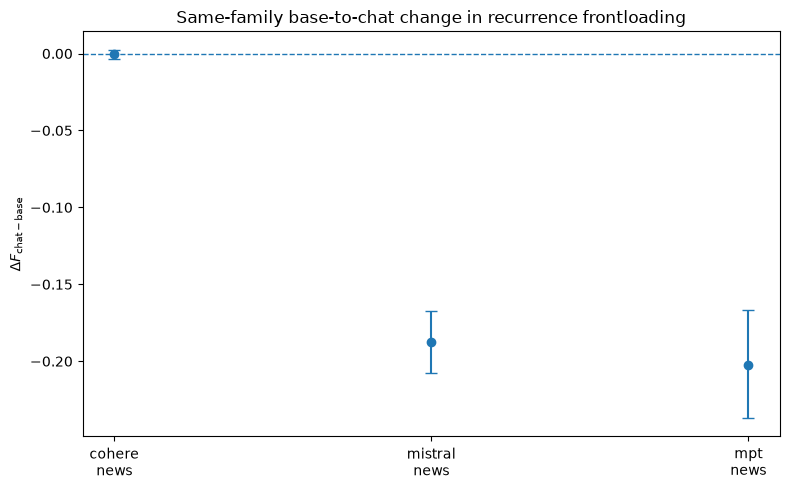

In [19]:

if len(summary):
    fig, ax = plt.subplots(figsize=(8, 5))

    labels = [
        f"{r.family}\n{r.domain}"
        for r in summary.itertuples()
    ]
    x = np.arange(len(summary))
    y = summary["delta_chat_minus_base"].to_numpy()
    yerr = np.vstack([
        y - summary["ci_low"].to_numpy(),
        summary["ci_high"].to_numpy() - y,
    ])

    ax.errorbar(x, y, yerr=yerr, fmt="o", capsize=4)
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel(r"$\Delta F_{\mathrm{chat-base}}$")
    ax.set_title("Same-family base-to-chat change in recurrence frontloading")
    fig.tight_layout()

    # Resolve reproduction root for outputs.
    OUT_DIR = None
    for p in PROJECT_CANDIDATES:
        if (p / "results").exists() and (p / "figures").exists():
            OUT_DIR = p / "results"
            FIG_DIR = p / "figures"
            break
        if (p / "reproduction" / "results").exists():
            OUT_DIR = p / "reproduction" / "results"
            FIG_DIR = p / "reproduction" / "figures"
            break

    if OUT_DIR is None:
        OUT_DIR = HERE / "results"
        FIG_DIR = HERE / "figures"

    OUT_DIR.mkdir(parents=True, exist_ok=True)
    FIG_DIR.mkdir(parents=True, exist_ok=True)

    fig_path = FIG_DIR / "frontloading_same_family_base_chat.pdf"
    fig.savefig(fig_path, bbox_inches="tight")
    print(fig_path)
    plt.show()



## 9. Save results and print interpretation


In [20]:

if "OUT_DIR" not in globals() or OUT_DIR is None:
    OUT_DIR = HERE / "results"
    OUT_DIR.mkdir(parents=True, exist_ok=True)

pairs_path = OUT_DIR / "frontloading_same_family_pairs.csv"
summary_path = OUT_DIR / "frontloading_same_family_summary.csv"
pooled_path = OUT_DIR / "frontloading_same_family_pooled.csv"

pairs.to_csv(pairs_path, index=False)
summary.to_csv(summary_path, index=False)
pooled.to_csv(pooled_path, index=False)

print(pairs_path)
print(summary_path)
print(pooled_path)

print("\nSAME-FAMILY BASE-vs-CHAT SUMMARY")
print("--------------------------------")

for r in summary.itertuples():
    print(
        f"{r.family:8s} {r.domain:4s} "
        f"n={r.n:3d} "
        f"base={r.mean_F_base:+.4f} "
        f"chat={r.mean_F_chat:+.4f} "
        f"Δ(chat-base)={r.delta_chat_minus_base:+.4f} "
        f"CI=[{r.ci_low:+.4f}, {r.ci_high:+.4f}]"
    )

if len(pooled):
    r = pooled.iloc[0]
    print()
    print(
        f"Pooled n={int(r['n_pairs'])}, "
        f"mean Δ={r['mean_delta_chat_minus_base']:+.4f}, "
        f"CI=[{r['ci_low']:+.4f}, {r['ci_high']:+.4f}], "
        f"dz={r['paired_dz']:+.3f}"
    )

if len(summary):
    all_negative = (summary["delta_chat_minus_base"] < 0).all()
    all_ci_negative = (summary["ci_high"] < 0).all()
    print()
    print("All family × domain point estimates negative:", all_negative)
    print("All family × domain 95% CIs below zero:", all_ci_negative)

    if all_negative:
        print(
            "\nInterpretation: within matched model families and fixed generation conditions, "
            "chat/post-trained variants exhibit lower recurrence frontloading than their base counterparts. "
            "This directly reduces the capability/family confound in the original cross-model regime comparison."
        )
    else:
        print(
            "\nInterpretation: the same-family results are heterogeneous. "
            "Do not attribute the original base/chat gap solely to post-training without inspecting each family."
        )


../results/frontloading_same_family_pairs.csv
../results/frontloading_same_family_summary.csv
../results/frontloading_same_family_pooled.csv

SAME-FAMILY BASE-vs-CHAT SUMMARY
--------------------------------
cohere   news n=300 base=+0.0033 chat=+0.0028 Δ(chat-base)=-0.0005 CI=[-0.0038, +0.0025]
mistral  news n=337 base=+0.1802 chat=-0.0072 Δ(chat-base)=-0.1874 CI=[-0.2079, -0.1673]
mpt      news n= 82 base=+0.1810 chat=-0.0212 Δ(chat-base)=-0.2021 CI=[-0.2370, -0.1670]

Pooled n=719, mean Δ=-0.1111, CI=[-0.1240, -0.0987], dz=-0.651

All family × domain point estimates negative: True
All family × domain 95% CIs below zero: False

Interpretation: within matched model families and fixed generation conditions, chat/post-trained variants exhibit lower recurrence frontloading than their base counterparts. This directly reduces the capability/family confound in the original cross-model regime comparison.
